# ML - Cenário Gasolina

In [117]:
import pandas as pd
import numpy as np

import plotly.graph_objs as go
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.arima.model import ARIMA
import plotly.express as px
import math

In [118]:
%matplotlib inline
warnings.filterwarnings("ignore")

In [119]:
#apontando para o caminho
Diretorio = r'C:\Users\Cinthia\Desktop\Tcc\DataSetTratado\tbl_combustivel_media_venda.csv'

In [120]:
#Lendo o arquivo
df = pd.DataFrame()
df = pd.read_csv(Diretorio, sep=";")

In [121]:
df

,Ano,Produto,Valor
0,2004,ETANOL,1.281185
1,2005,ETANOL,1.479791
2,2006,ETANOL,1.776138
3,2007,ETANOL,1.573799
4,2008,ETANOL,1.581506
5,2009,ETANOL,1.609015
6,2010,ETANOL,1.790473
7,2011,ETANOL,2.101510
8,2012,ETANOL,2.098404
9,2013,ETANOL,2.138045


In [122]:
df_media_consumo_ano_gasolina = df[(df.Produto=='GASOLINA')]

In [123]:
df_media_consumo_ano_gasolina

,Ano,Produto,Valor
18,2004,GASOLINA,2.139078
19,2005,GASOLINA,2.360970
20,2006,GASOLINA,2.589450
21,2007,GASOLINA,2.545285
22,2008,GASOLINA,2.543574
23,2009,GASOLINA,2.547026
24,2010,GASOLINA,2.604236
25,2011,GASOLINA,2.759646
26,2012,GASOLINA,2.766853
27,2013,GASOLINA,2.886324


In [124]:
df_media_consumo_ano_gasolina.reset_index(inplace=True)

In [125]:
df_media_consumo_ano_gasolina['Ano'] = df_media_consumo_ano_gasolina['Ano'].astype(str)
df_media_consumo_ano_gasolina['Valor'] = round(df_media_consumo_ano_gasolina['Valor'],2).astype(float)

In [126]:
df_media_consumo_ano_gasolina

,index,Ano,Produto,Valor
0,18,2004,GASOLINA,2.14
1,19,2005,GASOLINA,2.36
2,20,2006,GASOLINA,2.59
3,21,2007,GASOLINA,2.55
4,22,2008,GASOLINA,2.54
5,23,2009,GASOLINA,2.55
6,24,2010,GASOLINA,2.60
7,25,2011,GASOLINA,2.76
8,26,2012,GASOLINA,2.77
9,27,2013,GASOLINA,2.89


# 5.2 - Ridge Regression

In [127]:
df_media_consumo_ano_gasolina = df_media_consumo_ano_gasolina.drop(columns='Produto')

In [128]:
df_media_consumo_ano_gasolina = df_media_consumo_ano_gasolina.drop(columns='index')

In [129]:
df_media_consumo_ano_gasolina

,Ano,Valor
0,2004,2.14
1,2005,2.36
2,2006,2.59
3,2007,2.55
4,2008,2.54
5,2009,2.55
6,2010,2.60
7,2011,2.76
8,2012,2.77
9,2013,2.89


In [130]:
#cenário gasolina
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler(feature_range = (2.14, 6))
mc_df_scaled = sc.fit_transform(df_media_consumo_ano_gasolina.drop(columns = ['Ano']))

In [131]:
mc_df_scaled

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [132]:
mc_df_scaled.shape

(18, 1)

In [133]:
X = mc_df_scaled[:,:7]
y = mc_df_scaled[:,:7]

In [134]:
X

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [135]:
X.shape

(18, 1)

In [136]:
X[0:1]

array([[2.14]])

In [137]:
y

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [138]:
X = np.asarray(X)
y = np.asarray(y)
X.shape, y.shape

((18, 1), (18, 1))

In [139]:
X

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [140]:
y

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [141]:
split = int(0.70 * len(X))
X_treino = X[:split]
y_treino = y[:split]
X_teste = X[split:]
y_teste = y[split:]

In [142]:
X_treino.shape, y_treino.shape

((12, 1), (12, 1))

In [143]:
X_teste.shape, y_teste.shape

((6, 1), (6, 1))

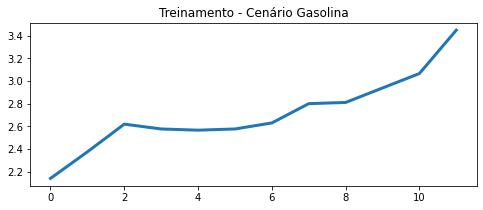

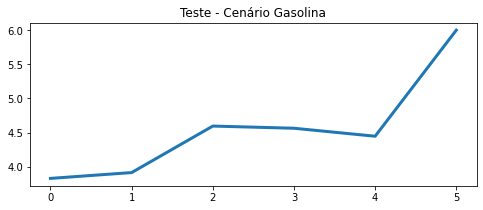

In [144]:
def show_plot_mc(data, title):
  plt.figure(figsize = (8, 3))
  plt.plot(data, linewidth = 3)
  plt.title(title)
  

show_plot_mc(X_treino, 'Treinamento - Cenário Gasolina')
show_plot_mc(X_teste, 'Teste - Cenário Gasolina')

In [145]:
from sklearn.linear_model import Ridge
regression_model = Ridge (alpha=0.1)
regression_model.fit(X_treino, y_treino)

Ridge(alpha=0.1)

In [146]:
lr_accuracy = regression_model.score(X_teste, y_teste)
print("Linear Regression Score: ", lr_accuracy)

Linear Regression Score:  0.9574735553904059


In [147]:
predicted_prices_mc = regression_model.predict(X)
predicted_prices_mc

array([[2.18233927],
       [2.3989491 ],
       [2.62540484],
       [2.58602123],
       [2.57617533],
       [2.58602123],
       [2.63525074],
       [2.79278516],
       [2.80263106],
       [2.92078188],
       [3.0389327 ],
       [3.39338516],
       [3.74783761],
       [3.82660483],
       [4.45674252],
       [4.42720482],
       [4.3188999 ],
       [5.75640153]])

In [148]:
len(predicted_prices_mc)

18

In [149]:
predicted_mc = []
for i in predicted_prices_mc:
  predicted_mc.append(i[0])

In [150]:
mc_fechamento = []
for i in mc_df_scaled:
  mc_fechamento.append(i[0])

In [151]:
mc_predicao = pd.DataFrame(columns = ['Ano' , 'ValorReal', 'ValorPreditivo'])
mc_predicao['Ano'] = df_media_consumo_ano_gasolina['Ano']
mc_predicao['ValorReal'] = mc_fechamento
mc_predicao['ValorPreditivo'] = predicted_mc
mc_predicao

,Ano,ValorReal,ValorPreditivo
0,2004,2.140000,2.182339
1,2005,2.373939,2.398949
2,2006,2.618512,2.625405
3,2007,2.575978,2.586021
4,2008,2.565344,2.576175
5,2009,2.575978,2.586021
6,2010,2.629146,2.635251
7,2011,2.799284,2.792785
8,2012,2.809917,2.802631
9,2013,2.937521,2.920782


In [152]:
def interactive_plot(Ano, title):
  fig = px.line(title = title)

  fig.update_layout(legend=dict(
    yanchor="top", y=0.99, xanchor="left", x=0.01))

  for i in Ano.columns[1:]:
    fig.add_scatter(x = Ano['Ano'], y = Ano[i], name = i)
    
  fig.show()



In [153]:
interactive_plot(mc_predicao, "Cenário Gasolina (Ridge Regression) - Preditivo")

In [154]:
import sklearn.metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Cálculo do erro
mse = mean_squared_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo'])
print('MSE: '+str(mse))
mae = mean_absolute_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo'])
print('MAE: '+str(mae))
rmse = math.sqrt(mean_squared_error(mc_predicao['ValorReal'], mc_predicao['ValorPreditivo']))
print('RMSE: '+str(rmse))

MSE: 0.007550038117845098
MAE: 0.05798400656686642
RMSE: 0.08689095532818762


# 5 - RNN - LSTM

In [155]:
training_data = df_media_consumo_ano_gasolina.iloc[:, 1:].values
training_data 

array([[2.14],
       [2.36],
       [2.59],
       [2.55],
       [2.54],
       [2.55],
       [2.6 ],
       [2.76],
       [2.77],
       [2.89],
       [3.01],
       [3.37],
       [3.73],
       [3.81],
       [4.45],
       [4.42],
       [4.31],
       [5.77]])

In [156]:
len(training_data) 

18

In [157]:
sc = MinMaxScaler(feature_range = (2.14, 6))
training_set_scaled = sc.fit_transform(training_data)

In [158]:
training_set_scaled

array([[2.14      ],
       [2.37393939],
       [2.6185124 ],
       [2.57597796],
       [2.56534435],
       [2.57597796],
       [2.62914601],
       [2.79928375],
       [2.80991736],
       [2.93752066],
       [3.06512397],
       [3.44793388],
       [3.8307438 ],
       [3.91581267],
       [4.59636364],
       [4.56446281],
       [4.44749311],
       [6.        ]])

In [159]:
X = []
y = []
for i in range(1, len(df_media_consumo_ano_gasolina)):
    X.append(training_set_scaled [i-1:i, 0]) 
    y.append(training_set_scaled [i, 0])

In [160]:
X

[array([2.14]),
 array([2.37393939]),
 array([2.6185124]),
 array([2.57597796]),
 array([2.56534435]),
 array([2.57597796]),
 array([2.62914601]),
 array([2.79928375]),
 array([2.80991736]),
 array([2.93752066]),
 array([3.06512397]),
 array([3.44793388]),
 array([3.8307438]),
 array([3.91581267]),
 array([4.59636364]),
 array([4.56446281]),
 array([4.44749311])]

In [161]:
y

[2.3739393939393936,
 2.6185123966942148,
 2.5759779614325065,
 2.56534435261708,
 2.5759779614325065,
 2.629146005509642,
 2.7992837465564735,
 2.809917355371901,
 2.937520661157025,
 3.0651239669421484,
 3.447933884297521,
 3.8307438016528925,
 3.9158126721763087,
 4.5963636363636375,
 4.564462809917355,
 4.447493112947658,
 6.0]

In [162]:
X = np.asarray(X)
y = np.asarray(y)

In [163]:
X.shape , y.shape

((17, 1), (17,))

In [164]:
split = int(0.7 * len(X))
X_train = X[:split]
y_train = y[:split]
X_test = X[split:]
y_test = y[split:]

In [165]:
X_train.shape , y_train.shape, X_test.shape, y_test.shape

((11, 1), (11,), (6, 1), (6,))

In [166]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
X_train.shape, X_test.shape

((11, 1, 1), (6, 1, 1))

In [167]:
X_train

array([[[2.14      ]],

       [[2.37393939]],

       [[2.6185124 ]],

       [[2.57597796]],

       [[2.56534435]],

       [[2.57597796]],

       [[2.62914601]],

       [[2.79928375]],

       [[2.80991736]],

       [[2.93752066]],

       [[3.06512397]]])

In [168]:
X_train.shape

(11, 1, 1)

In [169]:
from tensorflow import keras

In [170]:
inputs = keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2]))
x = keras.layers.LSTM(250, return_sequences= True)(inputs)
x = keras.layers.Dropout(0.1)(x) 
x = keras.layers.LSTM(250, return_sequences=True)(x)
x = keras.layers.Dropout(0.1)(x)
x = keras.layers.LSTM(250)(x)
outputs = keras.layers.Dense(1, activation='linear')(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss="mse")
model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 1, 1)]            0         
                                                                 
 lstm_3 (LSTM)               (None, 1, 250)            252000    
                                                                 
 dropout_2 (Dropout)         (None, 1, 250)            0         
                                                                 
 lstm_4 (LSTM)               (None, 1, 250)            501000    
                                                                 
 dropout_3 (Dropout)         (None, 1, 250)            0         
                                                                 
 lstm_5 (LSTM)               (None, 250)               501000    
                                                                 
 dense_1 (Dense)             (None, 1)                 251 

In [171]:
X_train.shape, y_train.shape

((11, 1, 1), (11,))

In [172]:
history = model.fit(
    X_train, y_train,
    epochs = 20,
    batch_size = 32,
    validation_split = 0.2
)

Epoch 1/20
1/1 [==============================] - 14s 14s/step - loss: 6.8583 - val_loss: 9.8491
Epoch 2/20
1/1 [==============================] - 0s 90ms/step - loss: 6.7820 - val_loss: 9.7360
Epoch 3/20
1/1 [==============================] - 0s 98ms/step - loss: 6.6962 - val_loss: 9.6012
Epoch 4/20
1/1 [==============================] - 0s 77ms/step - loss: 6.5914 - val_loss: 9.4370
Epoch 5/20
1/1 [==============================] - 0s 56ms/step - loss: 6.4658 - val_loss: 9.2371
Epoch 6/20
1/1 [==============================] - 0s 60ms/step - loss: 6.3257 - val_loss: 8.9953
Epoch 7/20
1/1 [==============================] - 0s 90ms/step - loss: 6.1321 - val_loss: 8.7057
Epoch 8/20
1/1 [==============================] - 0s 72ms/step - loss: 5.9274 - val_loss: 8.3614
Epoch 9/20
1/1 [==============================] - 0s 77ms/step - loss: 5.6825 - val_loss: 7.9560
Epoch 10/20
1/1 [==============================] - 0s 77ms/step - loss: 5.3822 - val_loss: 7.4823
Epoch 11/20
1/1 [============

In [173]:
predicted_LSTM = model.predict(X)

1/1 [==============================] - 2s 2s/step


In [174]:
predicted_LSTM

array([[2.1184912],
       [2.3344884],
       [2.5652566],
       [2.524796 ],
       [2.5147016],
       [2.524796 ],
       [2.575392 ],
       [2.7385747],
       [2.748834 ],
       [2.8724337],
       [2.996853 ],
       [3.3737037],
       [3.7531936],
       [3.8375363],
       [4.506754 ],
       [4.475736 ],
       [4.361633 ]], dtype=float32)

In [175]:
predicted_LSTM.shape

(17, 1)

In [176]:
test_predicted_LSTM = []

for i in predicted_LSTM:
  test_predicted_LSTM.append(i[0]) 

In [177]:
len(test_predicted_LSTM)

17

In [178]:
df_predicao_LSTM = pd.DataFrame(columns = ['Ano' , 'ValorReal', 'ValorPreditivo'])

In [179]:
df_predicao_LSTM['Ano'] = df_media_consumo_ano_gasolina[:-1]['Ano']

In [180]:
Fechamento_Scaled = []
for i in training_set_scaled:
  Fechamento_Scaled.append(i[0])

In [181]:
len(Fechamento_Scaled)

18

In [182]:
df_predicao_LSTM['ValorReal'] = Fechamento_Scaled[:-1]

In [183]:
df_predicao_LSTM['ValorPreditivo'] = test_predicted_LSTM

In [184]:
interactive_plot(df_predicao_LSTM, "Cenário Gasolina - LSTM")

In [185]:
#Cálculo do erro
mse = mean_squared_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo'])
print('MSE: '+str(mse))
mae = mean_absolute_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo'])
print('MAE: '+str(mae))
rmse = math.sqrt(mean_squared_error(df_predicao_LSTM['ValorReal'], df_predicao_LSTM['ValorPreditivo']))
print('RMSE: '+str(rmse))

MSE: 0.004281658882290588
MAE: 0.06296352692002741
RMSE: 0.06543438608476883
